### Top30 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [3]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [4]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

##### Scaling

In [4]:
scaler = StandardScaler()

In [6]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [5]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [8]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [6]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [10]:
# df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [7]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [8]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [9]:
for col in ['Ticker','Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [10]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [11]:
df_train1['Ticker_encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_encoded'] = label_encoder.transform(df_test1['Ticker'])

In [12]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [13]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [14]:
features = vif_cols.copy()
features.append("Quarter")

In [15]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 1, 11)
y_train shape: (42985,)
X_test shape: (10788, 1, 11)
y_test shape: (10788,)


In [16]:
ticker_encoded_train = df_train1['Ticker_encoded'].values
ticker_encoded_test = df_test1['Ticker_encoded'].values

In [17]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### TFT

In [18]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, LayerNormalization, Dropout, MultiHeadAttention, GRU, Concatenate, Embedding, Flatten, RepeatVector
from tensorflow.keras.models import Model

def gated_residual_network(x, hidden_units, dropout_rate=0.1):
    dense1 = Dense(hidden_units, activation='elu')(x)
    dropout = Dropout(dropout_rate)(dense1)
    dense2 = Dense(x.shape[-1])(dropout)
    gated_output = tf.keras.layers.Add()([x, dense2])
    norm = LayerNormalization()(gated_output)
    return norm

def build_tft_top30_model(input_shape, embedding_size, num_tickers, num_heads=4, hidden_units=16):
    # Inputs
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)

    # Merge static and temporal inputs
    merged_input = Concatenate(axis=-1)([ticker_embedding, continuous_input])

    # Gated Residual Network
    grn_output = gated_residual_network(merged_input, hidden_units)

    # Multi-Head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=hidden_units)(grn_output, grn_output)
    attention_output = LayerNormalization()(attention_output + grn_output)

    # Temporal processing (GRU)
    rnn_output = GRU(hidden_units, return_sequences=False)(attention_output)

    # Output layer
    output = Dense(1, activation='sigmoid')(rnn_output)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [19]:
num_tickers = len(label_encoder.classes_)

In [20]:
embedding_size

842

In [21]:
X_train.shape

(42985, 1, 11)

In [22]:
embedding_size

842

In [23]:

# Define tft model
tft_top30_model = build_tft_top30_model(X_train.shape, embedding_size, num_tickers)
tft_top30_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [24]:
df_train1['Ticker_encoded'].shape

(42985,)

In [25]:
X_train.shape

(42985, 1, 11)

In [26]:
y_test.shape

(10788,)

In [27]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30.keras



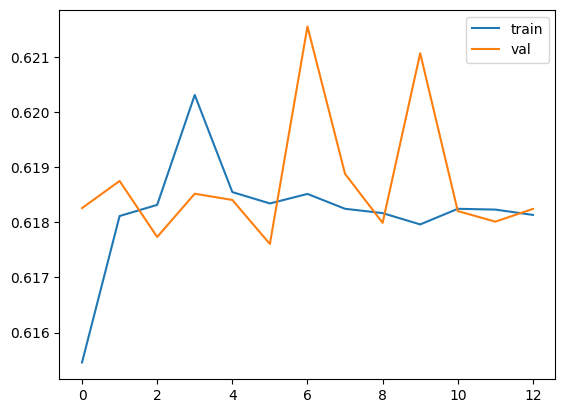

In [28]:
process_and_evaluate1(
    tft_top30_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_encoded']), np.array(df_test1['Ticker_encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\tft_top30.keras',epochs=30,batch_size=16
)

In [29]:
tft_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\tft_top30.keras')

In [30]:
pred_probs_test = tft_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = tft_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step


In [31]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [32]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [33]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [34]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [35]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.691520,0.504053,0.0,0.0,0.0,"[[29725, 0], [13260, 0]]",Train
1,0.785224,0.500520,0.0,0.0,0.0,"[[8471, 1], [2316, 0]]",Test


In [36]:
model_name = 'tft_top30'
top_n = 30

In [37]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [38]:
df_master = pd.read_excel(master_data_path)

In [39]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [116]:
# df_pred1.columns

In [40]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [41]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()
# if quarterly_returns_f2['Avg_Returns_Predicted'].isna().any():
#     print("there are quarters where there were no 1s by the model")
# else:
#     print("there are no quarters where there were no 1s by the model")
qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']

# set_summary_df2 = qtr_summary_df2.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']
# suffix_map = {
#     'qtr_summary_df2': '_thresh',
#     'qtr_summary_df': '_top'
# }


# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Add suffixes
# qtr_summary_df2_suff = add_suffix_to_cols(qtr_summary_df2_reset, suffix_map['qtr_summary_df2'], exclude_cols)
# qtr_summary_df_suff = add_suffix_to_cols(qtr_summary_df_reset, suffix_map['qtr_summary_df'], exclude_cols)
# ...existing code...

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_21524\4113010357.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_21524\4113010357.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_21524\4113010357.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.092318,0.136619,NaN,0.462237,-0.019376,0.369919,0.111694,0.325618,...,0,266,254,291,25,37,0,189,181,194
1,2005-06-30,Train,0.264620,0.317830,NaN,0.495418,0.045476,0.230799,0.219144,0.177589,...,0,271,258,292,21,34,0,184,177,193
2,2005-09-30,Train,0.085696,0.080140,NaN,0.180268,0.244277,0.094572,-0.158581,0.100127,...,0,279,273,289,10,16,0,176,162,196
3,2005-12-31,Train,0.242432,0.241485,NaN,0.407782,0.058583,0.165350,0.183849,0.166298,...,0,277,267,290,13,23,0,178,168,195
4,2006-03-31,Train,-0.078212,-0.102227,NaN,0.018142,0.187746,0.096354,-0.265958,0.120369,...,0,277,264,295,18,31,0,183,176,195


In [42]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [120]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [43]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.5064751 , 0.33137494, 0.33135223, 0.32396868, 0.31644472,
       0.3164132 , 0.31640902, 0.316409  , 0.31640896, 0.3164037 ,
       0.31325102, 0.29751384, 0.28907084, 0.28546402, 0.3644115 ,
       0.33135232, 0.3199541 , 0.3164167 , 0.31641167, 0.3164091 ,
       0.31640884, 0.3164088 , 0.31638265, 0.31203377, 0.311978  ,
       0.2975145 , 0.28900117, 0.28546435, 0.24177693, 0.42538467,
       0.3313537 , 0.33038896, 0.31642777, 0.31641302, 0.3164101 ,
       0.31640914, 0.31640866, 0.31640685, 0.31554386, 0.30601263,
       0.30559137, 0.42155218, 0.33144158, 0.33135775, 0.33135268,
       0.3306585 , 0.3164136 , 0.31641042, 0.31641006, 0.3164095 ,
       0.31640872, 0.31640616, 0.31640503, 0.3158805 , 0.31581205,
       0.30568063, 0.33063164, 0.3200252 , 0.31883648, 0.31641373,
       0.31641114, 0.31640917, 0.31640723, 0.31196347, 0.29458752,
       0.4240909 , 0.3306586 , 0.31640965, 0.31640702, 0.31639892,
       0.31641442, 0.31640926, 0.297636  , 0.28547066, 0.36564

In [44]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,8471,1,2316,63,8175,297,2253,109,7981,491,2207
Train,0,29725,0,13260,662,28347,1378,12598,1095,27420,2305,12165


In [45]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [46]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7636, precision=0.1750, recall=0.0272, f1=0.0471
Train: accuracy=0.6749, precision=0.3245, recall=0.0499, f1=0.0865

Metrics for _Top50:
Test: accuracy=0.7499, precision=0.1817, recall=0.0471, f1=0.0748
Train: accuracy=0.6634, precision=0.3221, recall=0.0826, f1=0.1315

Metrics for _Thresh:
Test: accuracy=0.7852, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.6915, precision=0.0000, recall=0.0000, f1=0.0000


In [47]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [126]:
qtr_summary_df[qtr_summary_df['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
66,2021-09-30,Train,0.2373,0.150289,5,768,25,24,5,748,45,24,1.519144,0.126554,1.281844,0.110746,1.368854,0.023736


In [127]:
qtr_summary_df2[qtr_summary_df2['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Thresh,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Thresh,delta_returns_pred_vs_index_Thresh
66,2021-09-30,Train,NaN,0,793,0,29,1.519144,0.126554,NaN,NaN


In [128]:
df_pred.columns

Index(['Ticker', 'Quarter', 'Target', 'Returns', 'Rank', 'Pred_Prob_cnn_top30',
       'Set', 'Top_30_Pred_Prob_cnn_top30', 'Top_50_Pred_Prob_cnn_top30',
       'Pred_Category_Top30', 'Pred_Category_Top50'],
      dtype='object')

In [129]:
df_pred1.columns

Index(['Ticker', 'Quarter', 'Target', 'Returns', 'Rank', 'Pred_Prob_cnn_top30',
       'Set', 'Pred_Prob_Threshold_cnn_top30', 'Pred_Category'],
      dtype='object')

In [130]:
merged_qtr_summary[merged_qtr_summary['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
66,2021-09-30,Train,0.2373,0.150289,NaN,1.519144,0.126554,1.281844,0.110746,1.368854,...,0,768,748,793,25,45,0,24,24,29


In [48]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [49]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.5064751 , 0.33137494, 0.33135223, 0.32396868, 0.31644472,
       0.3164132 , 0.31640902, 0.316409  , 0.31640896, 0.3164037 ,
       0.31325102, 0.29751384, 0.28907084, 0.28546402, 0.3644115 ,
       0.33135232, 0.3199541 , 0.3164167 , 0.31641167, 0.3164091 ,
       0.31640884, 0.3164088 , 0.31638265, 0.31203377, 0.311978  ,
       0.2975145 , 0.28900117, 0.28546435, 0.24177693, 0.42538467,
       0.3313537 , 0.33038896, 0.31642777, 0.31641302, 0.3164101 ,
       0.31640914, 0.31640866, 0.31640685, 0.31554386, 0.30601263,
       0.30559137, 0.42155218, 0.33144158, 0.33135775, 0.33135268,
       0.3306585 , 0.3164136 , 0.31641042, 0.31641006, 0.3164095 ,
       0.31640872, 0.31640616, 0.31640503, 0.3158805 , 0.31581205,
       0.30568063, 0.33063164, 0.3200252 , 0.31883648, 0.31641373,
       0.31641114, 0.31640917, 0.31640723, 0.31196347, 0.29458752,
       0.4240909 , 0.3306586 , 0.31640965, 0.31640702, 0.31639892,
       0.31641442, 0.31640926, 0.297636  , 0.28547066, 0.36564

In [50]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.306907
std          0.009973
min          0.241777
25%          0.297514
50%          0.297514
75%          0.316409
max          0.506475
Name: Pred_Prob_tft_top30, dtype: float64

In [51]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [135]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,10441,1,346,13,10095,347,333,17,9859,583,329
Train,0,41056,0,1929,113,39129,1927,1816,146,37802,3254,1783


In [52]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [53]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_21524\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_21524\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [138]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.196712,0.125528,0.0,1.455923,-0.019376,1.259211,0.216088,1.330395,...,0,429,409,457,28,48,0,26,26,28
1,2005-06-30,Train,0.533244,0.435100,0.0,1.790164,0.045476,1.256920,0.487769,1.355064,...,0,429,409,458,29,49,0,26,26,27
2,2005-09-30,Train,0.114253,0.095668,0.0,0.496120,0.244277,0.381866,-0.130024,0.400452,...,0,429,410,456,27,46,0,26,25,29
3,2005-12-31,Train,0.238738,0.261315,0.0,1.147137,0.058583,0.908399,0.180154,0.885822,...,0,430,411,457,27,46,0,25,24,28
4,2006-03-31,Train,-0.071694,-0.097075,0.0,0.772814,0.187746,0.844508,-0.259440,0.869889,...,0,434,414,461,27,47,0,26,26,29


In [139]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top30,Set,Top_30_Pred_Prob_cnn_top30,Top_50_Pred_Prob_cnn_top30,Pred_Category_Top30,Pred_Category_Top50
0,innovaca,2024-12-31,0,-0.212076,489.0,0.139652,Test,True,True,FP,FP
1,avalon,2024-12-31,0,-0.214160,494.0,0.139644,Test,True,True,FP,FP
2,adanigr,2024-12-31,0,-0.088450,240.0,0.139644,Test,True,True,FP,FP
3,azad,2024-12-31,0,-0.210539,478.0,0.139642,Test,True,True,FP,FP
4,paras,2024-12-31,0,-0.049891,176.0,0.139638,Test,True,True,FP,FP


In [140]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.196712,0.125528,2,429,28,26,2,409,48,26,1.455923,-0.019376,1.259211,0.216088,1.330395,0.144904
1,2005-06-30,Train,0.533244,0.435100,1,429,29,26,1,409,49,26,1.790164,0.045476,1.256920,0.487769,1.355064,0.389625
2,2005-09-30,Train,0.114253,0.095668,3,429,27,26,4,410,46,25,0.496120,0.244277,0.381866,-0.130024,0.400452,-0.148609
3,2005-12-31,Train,0.238738,0.261315,3,430,27,25,4,411,46,24,1.147137,0.058583,0.908399,0.180154,0.885822,0.202732
4,2006-03-31,Train,-0.071694,-0.097075,3,434,27,26,3,414,47,26,0.772814,0.187746,0.844508,-0.259440,0.869889,-0.284821


In [54]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [55]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top30\3yrs_as_test_data_ts\Pred_Vs_Act_TFT_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top30 Xform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [146]:
# train_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\train_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# test_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\test_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# master_data_path = r"D:\FY25-26\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

# df_train = pd.read_excel(train_data_path)
# df_test = pd.read_excel(test_data_path)
# df_master = pd.read_excel(master_data_path)

# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [153]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [10]:
from scipy.stats import skew

In [11]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [156]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [12]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [13]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [14]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transform_map = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transform_map[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


#### Power xforms

In [15]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }

def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transform_map.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 1, 11)
y_train shape: (42985,)
X_test shape: (10788, 1, 11)
y_test shape: (10788,)


In [16]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [17]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [18]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [19]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [20]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [21]:
features = vif_cols.copy()
features.append("Quarter")

In [22]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [23]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### TFT

In [24]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, LayerNormalization, Dropout, MultiHeadAttention, GRU, Concatenate, Embedding, Flatten, RepeatVector
from tensorflow.keras.models import Model

def gated_residual_network(x, hidden_units, dropout_rate=0.1):
    dense1 = Dense(hidden_units, activation='elu')(x)
    dropout = Dropout(dropout_rate)(dense1)
    dense2 = Dense(x.shape[-1])(dropout)
    gated_output = tf.keras.layers.Add()([x, dense2])
    norm = LayerNormalization()(gated_output)
    return norm

def build_tft_top30_xform_model(input_shape, embedding_size, num_tickers, num_heads=4, hidden_units=16):
    # Inputs
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)

    # Merge static and temporal inputs
    merged_input = Concatenate(axis=-1)([ticker_embedding, continuous_input])

    # Gated Residual Network
    grn_output = gated_residual_network(merged_input, hidden_units)

    # Multi-Head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=hidden_units)(grn_output, grn_output)
    attention_output = LayerNormalization()(attention_output + grn_output)

    # Temporal processing (GRU)
    rnn_output = GRU(hidden_units, return_sequences=False)(attention_output)

    # Output layer
    output = Dense(1, activation='sigmoid')(rnn_output)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [25]:
num_tickers = len(label_encoder.classes_)

In [26]:

# Define tft model
tft_xform_model = build_tft_top30_xform_model(X_train.shape, embedding_size, num_tickers)
tft_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [181]:
# X_train = X_train.reshape(-1, 11)
# X_test = X_test.reshape(-1, 11)

In [27]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top30_xform.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\

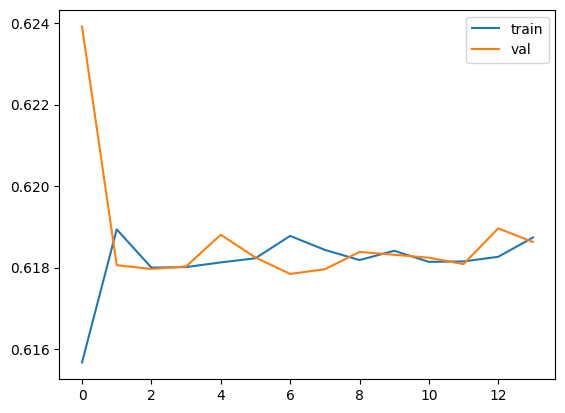

In [28]:
process_and_evaluate1(
    tft_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\tft_top30_xform.keras',epochs=30,batch_size=16
)

In [29]:
tft_x_from_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\tft_top30_xform.keras')

In [30]:
pred_probs_test = tft_x_from_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = tft_x_from_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step


In [31]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [32]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [33]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [34]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [35]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.691102,0.50149,0.200000,0.000452,0.000903,"[[29701, 24], [13254, 6]]",Train
1,0.784483,0.49734,0.090909,0.000432,0.000859,"[[8462, 10], [2315, 1]]",Test


In [36]:
model_name = 'tft_top30_xform'
top_n = 30

In [37]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [38]:
df_master = pd.read_excel(master_data_path)

In [39]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [42]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()
# if quarterly_returns_f2['Avg_Returns_Predicted'].isna().any():
#     print("there are quarters where there were no 1s by the model")
# else:
#     print("there are no quarters where there were no 1s by the model")
qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']

exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]

# merged_qtr_summary.reset_index(inplace=True)

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1

for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")

if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")


C:\Users\43737\AppData\Local\Temp\ipykernel_28884\4071300849.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_28884\4071300849.py:55: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_28884\4071300849.py:58: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 


Metrics for _Top30:
Test: accuracy=0.7633, precision=0.1694, recall=0.0263, f1=0.0456
Train: accuracy=0.6711, precision=0.2848, recall=0.0438, f1=0.0759

Metrics for _Top50:
Test: accuracy=0.7466, precision=0.1517, recall=0.0393, f1=0.0624
Train: accuracy=0.6588, precision=0.2932, recall=0.0752, f1=0.1197

Metrics for _Thresh:
Test: accuracy=0.7845, precision=0.0909, recall=0.0004, f1=0.0009
Train: accuracy=0.6911, precision=0.2000, recall=0.0005, f1=0.0009
All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [41]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3


,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,1,8462,10,2315,61,8173,299,2255,91,7963,509,2225
Train,6,29701,24,13254,581,28266,1459,12679,997,27322,2403,12263


In [43]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_28884\2271013527.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_28884\2271013527.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.174959,0.188795,0.000000,0.462237,-0.019376,0.287278,0.194335,0.273442,...,0,269,258,291,22,33,0,186,177,194
1,2005-06-30,Train,0.274977,0.303351,0.612245,0.495418,0.045476,0.220442,0.229501,0.192067,...,1,272,260,292,20,32,0,183,175,192
2,2005-09-30,Train,0.038855,0.025431,0.022958,0.180268,0.244277,0.141413,-0.205422,0.154837,...,0,271,256,288,18,33,1,184,179,196
3,2005-12-31,Train,0.087349,0.128350,0.022958,0.407782,0.058583,0.320434,0.028765,0.279432,...,0,269,256,290,21,34,0,186,179,195
4,2006-03-31,Train,-0.175298,-0.163210,0.022958,0.018142,0.187746,0.193439,-0.363044,0.181351,...,0,270,261,295,25,34,0,190,179,195


In [44]:
(merged_qtr_summary[merged_qtr_summary['Set']=='Train']['Avg_Returns_Predicted_Thresh']==0).sum()


np.int64(1)

In [45]:
df_pred.tail()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_tft_top30_xform,Set,Top_30_Pred_Prob_tft_top30_xform,Top_50_Pred_Prob_tft_top30_xform,Pred_Category_Top30,Pred_Category_Top50
53768,siya,2005-03-31,1,0.532946,71.0,0.289139,Train,False,False,FN,FN
53769,jsp,2005-03-31,0,-0.178571,469.0,0.289139,Train,False,False,TN,TN
53770,dolphino,2005-03-31,1,-0.010000,397.0,0.289136,Train,False,False,FN,FN
53771,volt,2005-03-31,0,0.017038,357.0,0.289106,Train,False,False,TN,TN
53772,atxl,2005-03-31,1,0.026668,342.0,0.288955,Train,False,False,FN,FN


In [200]:
df_pred['Set'].unique()

array(['Test', 'Train'], dtype=object)

In [201]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.146208,0.140359,1,428,29,27,2,409,48,26,1.455923,-0.019376,1.309715,0.165584,1.315564,0.159735
1,2005-06-30,Train,0.277085,0.269094,0,428,30,27,0,408,50,27,1.790164,0.045476,1.513079,0.231610,1.521071,0.223618
2,2005-09-30,Train,0.078312,0.078964,1,427,29,28,2,408,48,27,0.496120,0.244277,0.417808,-0.165965,0.417156,-0.165313
3,2005-12-31,Train,0.306326,0.276888,3,430,27,25,3,410,47,25,1.147137,0.058583,0.840811,0.247742,0.870249,0.218305
4,2006-03-31,Train,-0.100484,-0.107827,2,433,28,27,3,414,47,26,0.772814,0.187746,0.873298,-0.288230,0.880641,-0.295573


In [46]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [203]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,10442,0,346,8,10090,352,338,10,9852,590,336
Train,0,41056,0,1929,40,39056,2000,1889,81,37737,3319,1848


In [47]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top30\3yrs_as_test_data_ts\Pred_Vs_Act_TFT_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 50 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [207]:
# train_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\train_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# test_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\test_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# master_data_path = r"D:\FY25-26\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

# df_train = pd.read_excel(train_data_path)
# df_test = pd.read_excel(test_data_path)
# df_master = pd.read_excel(master_data_path)

# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

##### Scaling

In [9]:
scaler = StandardScaler()

In [214]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [10]:
df_train['Target'] = np.where(df_train['Rank']<=50,1,0)
df_test['Target'] = np.where(df_test['Rank']<=50,1,0)

In [216]:
# df_train.drop()

In [11]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [218]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [12]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [13]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [14]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [15]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [16]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [17]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [225]:
# df_train1['Ticker_Encoded']

In [18]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [19]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [20]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [21]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 1, 11)
y_train shape: (42985,)
X_test shape: (10788, 1, 11)
y_test shape: (10788,)


In [22]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [23]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### TFT

In [24]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, LayerNormalization, Dropout, MultiHeadAttention, GRU, Concatenate, Embedding, Flatten, RepeatVector
from tensorflow.keras.models import Model

def gated_residual_network(x, hidden_units, dropout_rate=0.1):
    dense1 = Dense(hidden_units, activation='elu')(x)
    dropout = Dropout(dropout_rate)(dense1)
    dense2 = Dense(x.shape[-1])(dropout)
    gated_output = tf.keras.layers.Add()([x, dense2])
    norm = LayerNormalization()(gated_output)
    return norm

def build_tft_top50_model(input_shape, embedding_size, num_tickers, num_heads=4, hidden_units=16):
    # Inputs
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)

    # Merge static and temporal inputs
    merged_input = Concatenate(axis=-1)([ticker_embedding, continuous_input])

    # Gated Residual Network
    grn_output = gated_residual_network(merged_input, hidden_units)

    # Multi-Head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=hidden_units)(grn_output, grn_output)
    attention_output = LayerNormalization()(attention_output + grn_output)

    # Temporal processing (GRU)
    rnn_output = GRU(hidden_units, return_sequences=False)(attention_output)

    # Output layer
    output = Dense(1, activation='sigmoid')(rnn_output)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [25]:
num_tickers = len(label_encoder.classes_)

In [26]:

# Define tft model
tft_top50_model = build_tft_top50_model(X_train.shape, embedding_size, num_tickers)
tft_top50_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [27]:
X_train.shape

(42985, 1, 11)

In [28]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"

In [28]:
y_train.shape

(42985,)


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50.keras



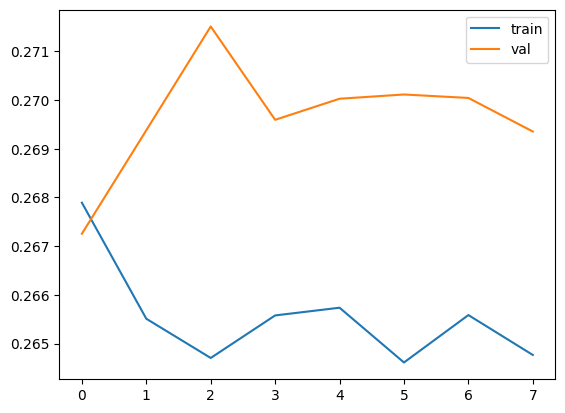

In [29]:
process_and_evaluate1(
    tft_top50_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\tft_top50.keras',epochs=40,batch_size=8
)

In [30]:
tft_top50_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\tft_top50.keras')

In [31]:
pred_probs_test = tft_top50_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = tft_top50_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [32]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [33]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [34]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [35]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [36]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.925230,0.528455,0.0,0.0,0.0,"[[39771, 0], [3214, 0]]",Train
1,0.946885,0.510044,0.0,0.0,0.0,"[[10215, 0], [573, 0]]",Test


In [37]:
model_name = 'tft_top50'
top_n = 30

In [38]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [39]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_18752\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_18752\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_18752\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.098875,0.142608,NaN,1.165694,-0.019376,1.066819,0.118251,1.023086,...,0,408,390,438,30,48,0,47,45,47
1,2005-06-30,Train,0.313379,0.320381,NaN,1.375535,0.045476,1.062156,0.267903,1.055154,...,0,413,397,439,26,42,0,42,38,46
2,2005-09-30,Train,0.056950,0.093984,NaN,0.426376,0.244277,0.369426,-0.187327,0.332392,...,0,409,393,436,27,43,0,46,42,49
3,2005-12-31,Train,0.244512,0.195627,NaN,0.932621,0.058583,0.688109,0.185929,0.736993,...,0,409,390,437,28,47,0,46,45,48
4,2006-03-31,Train,-0.101520,-0.116377,NaN,0.503488,0.187746,0.605008,-0.289266,0.619865,...,0,414,395,441,27,46,0,46,45,49


In [40]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.True_

In [41]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [42]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.15745543, 0.11147957, 0.09508488, 0.09255793, 0.08627633,
       0.08361053, 0.0836105 , 0.0836103 , 0.0836103 , 0.07575157,
       0.07243018, 0.06763455, 0.06761996, 0.0676199 , 0.04158757,
       0.10550518, 0.09490893, 0.08714271, 0.08431075, 0.08361044,
       0.08361033, 0.08041158, 0.08006275, 0.08005691, 0.07252283,
       0.06761993, 0.06761992, 0.05192938, 0.15745555, 0.15745546,
       0.12287945, 0.12253246, 0.11121131, 0.08503655, 0.08360799,
       0.08292504, 0.08171898, 0.07275595, 0.06761999, 0.05225804,
       0.05052483, 0.12297899, 0.11848945, 0.11143477, 0.1113092 ,
       0.09474237, 0.09322909, 0.08361054, 0.08054002, 0.06799753,
       0.06763066, 0.06762152, 0.0519677 , 0.02397659, 0.14876816,
       0.12297958, 0.12297896, 0.12293471, 0.1114681 , 0.09913428,
       0.08712753, 0.08262677, 0.08086404, 0.08016028, 0.08005851,
       0.07287886, 0.07247113, 0.15728076, 0.12856239, 0.09483761,
       0.09117418, 0.083521  , 0.08351015, 0.07248361, 0.06768

In [43]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,10215,0,573,13,9868,347,560,22,9637,578,551
Train,0,39771,0,3214,107,37838,1933,3107,194,36565,3206,3020


In [44]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [45]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.9159, precision=0.0361, recall=0.0227, f1=0.0279
Train: accuracy=0.8827, precision=0.0525, recall=0.0333, f1=0.0407

Metrics for _Top50:
Test: accuracy=0.8953, precision=0.0367, recall=0.0384, f1=0.0375
Train: accuracy=0.8552, precision=0.0571, recall=0.0604, f1=0.0587

Metrics for _Thresh:
Test: accuracy=0.9469, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.9252, precision=0.0000, recall=0.0000, f1=0.0000


In [46]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [47]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [48]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.15745543, 0.11147957, 0.09508488, 0.09255793, 0.08627633,
       0.08361053, 0.0836105 , 0.0836103 , 0.0836103 , 0.07575157,
       0.07243018, 0.06763455, 0.06761996, 0.0676199 , 0.04158757,
       0.10550518, 0.09490893, 0.08714271, 0.08431075, 0.08361044,
       0.08361033, 0.08041158, 0.08006275, 0.08005691, 0.07252283,
       0.06761993, 0.06761992, 0.05192938, 0.15745555, 0.15745546,
       0.12287945, 0.12253246, 0.11121131, 0.08503655, 0.08360799,
       0.08292504, 0.08171898, 0.07275595, 0.06761999, 0.05225804,
       0.05052483, 0.12297899, 0.11848945, 0.11143477, 0.1113092 ,
       0.09474237, 0.09322909, 0.08361054, 0.08054002, 0.06799753,
       0.06763066, 0.06762152, 0.0519677 , 0.02397659, 0.14876816,
       0.12297958, 0.12297896, 0.12293471, 0.1114681 , 0.09913428,
       0.08712753, 0.08262677, 0.08086404, 0.08016028, 0.08005851,
       0.07287886, 0.07247113, 0.15728076, 0.12856239, 0.09483761,
       0.09117418, 0.083521  , 0.08351015, 0.07248361, 0.06768

In [49]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.073844
std          0.008413
min          0.023977
25%          0.067620
50%          0.067620
75%          0.083610
max          0.172219
Name: Pred_Prob_tft_top50, dtype: float64

In [50]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [51]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,10215,0,573,13,9868,347,560,22,9637,578,551
Train,0,39771,0,3214,107,37838,1933,3107,194,36565,3206,3020


In [52]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [53]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_18752\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_18752\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [54]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.098875,0.142608,0.0,1.165694,-0.019376,1.066819,0.118251,1.023086,...,0,408,390,438,30,48,0,47,45,47
1,2005-06-30,Train,0.313379,0.320381,0.0,1.375535,0.045476,1.062156,0.267903,1.055154,...,0,413,397,439,26,42,0,42,38,46
2,2005-09-30,Train,0.056950,0.093984,0.0,0.426376,0.244277,0.369426,-0.187327,0.332392,...,0,409,393,436,27,43,0,46,42,49
3,2005-12-31,Train,0.244512,0.195627,0.0,0.932621,0.058583,0.688109,0.185929,0.736993,...,0,409,390,437,28,47,0,46,45,48
4,2006-03-31,Train,-0.101520,-0.116377,0.0,0.503488,0.187746,0.605008,-0.289266,0.619865,...,0,414,395,441,27,46,0,46,45,49


In [264]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_tft_top50,Set,Top_30_Pred_Prob_tft_top50,Top_50_Pred_Prob_tft_top50,Pred_Category_Top30,Pred_Category_Top50
0,iib,2024-12-31,0,NaN,NaN,0.168282,Test,True,True,FP,FP
1,tcs,2024-12-31,0,-0.119334,301.0,0.086750,Test,True,True,FP,FP
2,info,2024-12-31,0,NaN,NaN,0.086750,Test,True,True,FP,FP
3,huvr,2024-12-31,0,NaN,NaN,0.086750,Test,True,True,FP,FP
4,hclt,2024-12-31,0,NaN,NaN,0.086750,Test,True,True,FP,FP


In [265]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.199278,0.224479,3,411,27,44,5,393,45,42,1.165694,-0.019376,0.966416,0.218654,0.941215,0.243854
1,2005-06-30,Train,0.337023,0.278242,5,414,25,41,5,394,45,41,1.375535,0.045476,1.038512,0.291547,1.097293,0.232766
2,2005-09-30,Train,0.086981,0.079991,3,409,27,46,3,389,47,46,0.426376,0.244277,0.339395,-0.157296,0.346385,-0.164286
3,2005-12-31,Train,0.251140,0.195813,4,411,26,44,4,391,46,44,0.932621,0.058583,0.681480,0.192557,0.736808,0.137230
4,2006-03-31,Train,-0.170911,-0.164228,0,411,30,49,1,392,49,48,0.503488,0.187746,0.674400,-0.358657,0.667717,-0.351974


In [55]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [56]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top50\3yrs_as_test_data_ts\Pred_Vs_Act_TFT_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top50 xform

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [3]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [4]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [5]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [6]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [7]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [8]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [9]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [10]:
df_train[df_train['Target']==1]['Rank'].max()

np.float64(860.0)

In [11]:
df_train['Target'] = np.where(df_train['Rank']<=50,1,0)
df_test['Target'] = np.where(df_test['Rank']<=50,1,0)

In [12]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [277]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [13]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [279]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [14]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [15]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transforms = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transforms[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [16]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

#### Power xforms

In [17]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }

def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transforms.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 1, 11)
y_train shape: (42985,)
X_test shape: (10788, 1, 11)
y_test shape: (10788,)


In [18]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [19]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [20]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [21]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [22]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [23]:
features = vif_cols.copy()
features.append("Quarter")

In [24]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [25]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=5, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### TFT

In [26]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, LayerNormalization, Dropout, MultiHeadAttention, GRU, Concatenate, Embedding, Flatten, RepeatVector
from tensorflow.keras.models import Model

def gated_residual_network(x, hidden_units, dropout_rate=0.1):
    dense1 = Dense(hidden_units, activation='elu')(x)
    dropout = Dropout(dropout_rate)(dense1)
    dense2 = Dense(x.shape[-1])(dropout)
    gated_output = tf.keras.layers.Add()([x, dense2])
    norm = LayerNormalization()(gated_output)
    return norm

def build_tft_top50_xform_model(input_shape, embedding_size, num_tickers, num_heads=4, hidden_units=16):
    # Inputs
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)

    # Merge static and temporal inputs
    merged_input = Concatenate(axis=-1)([ticker_embedding, continuous_input])

    # Gated Residual Network
    grn_output = gated_residual_network(merged_input, hidden_units)

    # Multi-Head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=hidden_units)(grn_output, grn_output)
    attention_output = LayerNormalization()(attention_output + grn_output)

    # Temporal processing (GRU)
    rnn_output = GRU(hidden_units, return_sequences=False)(attention_output)

    # Output layer
    output = Dense(1, activation='sigmoid')(rnn_output)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [27]:
num_tickers = len(label_encoder.classes_)

In [28]:

# Define tft model
tft_top50_xform_model = build_tft_top50_xform_model(X_train.shape, embedding_size, num_tickers)
tft_top50_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [307]:
X_train.shape

(42985, 1, 11)

In [30]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top50_xform.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\

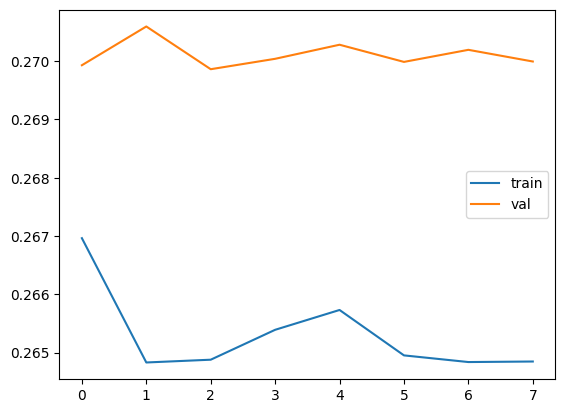

In [31]:
process_and_evaluate1(
    tft_top50_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\tft_top50_xform.keras',epochs=30,batch_size=16
)

In [32]:
tft_top50_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\tft_top50_xform.keras')

In [33]:
pred_probs_test = tft_top50_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = tft_top50_xform_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step


In [34]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [35]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [36]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [37]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [38]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.925230,0.487804,0.0,0.0,0.0,"[[39771, 0], [3214, 0]]",Train
1,0.946885,0.470517,0.0,0.0,0.0,"[[10215, 0], [573, 0]]",Test


In [39]:
model_name = 'tft_top50_xform'
top_n = 30

In [40]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [41]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_17900\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_17900\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_17900\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.070200,0.092595,NaN,1.165694,-0.019376,1.095494,0.089576,1.073099,...,0,408,389,438,30,49,0,47,46,47
1,2005-06-30,Train,0.254543,0.286579,NaN,1.375535,0.045476,1.120993,0.209067,1.088956,...,0,409,392,439,30,47,0,46,43,46
2,2005-09-30,Train,0.073497,0.080164,NaN,0.426376,0.244277,0.352879,-0.170780,0.346212,...,0,408,391,436,28,45,0,47,44,49
3,2005-12-31,Train,0.262314,0.267153,NaN,0.932621,0.058583,0.670307,0.203731,0.665468,...,0,410,394,437,27,43,0,45,41,48
4,2006-03-31,Train,-0.135885,-0.138643,NaN,0.503488,0.187746,0.639373,-0.323631,0.642131,...,0,412,394,441,29,47,0,48,46,49


In [42]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.True_

In [43]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [44]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.10135406, 0.10122548, 0.1009824 , 0.09600368, 0.07816397,
       0.07637455, 0.0760539 , 0.0743671 , 0.07393114, 0.0738935 ,
       0.07388025, 0.07387787, 0.07387679, 0.07387678, 0.07387676,
       0.07140573, 0.07123062, 0.07122264, 0.07119627, 0.07116157,
       0.07116141, 0.07115347, 0.0711531 , 0.07115066, 0.07114828,
       0.07114445, 0.07114414, 0.07114392, 0.0711437 , 0.07114351,
       0.07114322, 0.07114321, 0.07114301, 0.07114282, 0.07114279,
       0.0711427 , 0.07114266, 0.07114264, 0.0711426 , 0.07114258,
       0.07114256, 0.07114255, 0.07114252, 0.0711425 , 0.07114249,
       0.07114247, 0.07114245, 0.07114244, 0.06636931, 0.06497063,
       0.05702455, 0.05315304, 0.05222527, 0.04768806, 0.0425455 ,
       0.03715823, 0.03557918, 0.0354711 , 0.01757339, 0.01021454,
       0.10091905, 0.09686917, 0.07572012, 0.07436441, 0.07395045,
       0.07390727, 0.07387764, 0.07387725, 0.07387702, 0.07171593,
       0.07169618, 0.07162783, 0.07128938, 0.07119823, 0.07118

In [45]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,10215,0,573,8,9863,352,565,13,9628,587,560
Train,0,39771,0,3214,96,37827,1944,3118,172,36543,3228,3042


In [46]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [47]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.9150, precision=0.0222, recall=0.0140, f1=0.0171
Train: accuracy=0.8822, precision=0.0471, recall=0.0299, f1=0.0365

Metrics for _Top50:
Test: accuracy=0.8937, precision=0.0217, recall=0.0227, f1=0.0222
Train: accuracy=0.8541, precision=0.0506, recall=0.0535, f1=0.0520

Metrics for _Thresh:
Test: accuracy=0.9469, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.9252, precision=0.0000, recall=0.0000, f1=0.0000


In [48]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [49]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [50]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.10135406, 0.10122548, 0.1009824 , 0.09600368, 0.07816397,
       0.07637455, 0.0760539 , 0.0743671 , 0.07393114, 0.0738935 ,
       0.07388025, 0.07387787, 0.07387679, 0.07387678, 0.07387676,
       0.07140573, 0.07123062, 0.07122264, 0.07119627, 0.07116157,
       0.07116141, 0.07115347, 0.0711531 , 0.07115066, 0.07114828,
       0.07114445, 0.07114414, 0.07114392, 0.0711437 , 0.07114351,
       0.07114322, 0.07114321, 0.07114301, 0.07114282, 0.07114279,
       0.0711427 , 0.07114266, 0.07114264, 0.0711426 , 0.07114258,
       0.07114256, 0.07114255, 0.07114252, 0.0711425 , 0.07114249,
       0.07114247, 0.07114245, 0.07114244, 0.06636931, 0.06497063,
       0.05702455, 0.05315304, 0.05222527, 0.04768806, 0.0425455 ,
       0.03715823, 0.03557918, 0.0354711 , 0.01757339, 0.01021454,
       0.10091905, 0.09686917, 0.07572012, 0.07436441, 0.07395045,
       0.07390727, 0.07387764, 0.07387725, 0.07387702, 0.07171593,
       0.07169618, 0.07162783, 0.07128938, 0.07119823, 0.07118

In [51]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.072470
std          0.004383
min          0.010208
25%          0.071142
50%          0.073877
75%          0.073877
max          0.102167
Name: Pred_Prob_tft_top50_xform, dtype: float64

In [52]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [331]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,10215,0,573,5,9860,355,568,12,9627,588,561
Train,0,39771,0,3214,96,37827,1944,3118,177,36548,3223,3037


In [53]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [54]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_17900\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_17900\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [55]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.070200,0.092595,0.0,1.165694,-0.019376,1.095494,0.089576,1.073099,...,0,408,389,438,30,49,0,47,46,47
1,2005-06-30,Train,0.254543,0.286579,0.0,1.375535,0.045476,1.120993,0.209067,1.088956,...,0,409,392,439,30,47,0,46,43,46
2,2005-09-30,Train,0.073497,0.080164,0.0,0.426376,0.244277,0.352879,-0.170780,0.346212,...,0,408,391,436,28,45,0,47,44,49
3,2005-12-31,Train,0.262314,0.267153,0.0,0.932621,0.058583,0.670307,0.203731,0.665468,...,0,410,394,437,27,43,0,45,41,48
4,2006-03-31,Train,-0.135885,-0.138643,0.0,0.503488,0.187746,0.639373,-0.323631,0.642131,...,0,412,394,441,29,47,0,48,46,49


In [56]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_tft_top50_xform,Set,Top_30_Pred_Prob_tft_top50_xform,Top_50_Pred_Prob_tft_top50_xform,Pred_Category_Top30,Pred_Category_Top50
0,honasa,2024-12-31,0,-0.091458,251.0,0.101354,Test,True,True,FP,FP
1,parkhote,2024-12-31,0,-0.205598,467.0,0.101225,Test,True,True,FP,FP
2,ireda,2024-12-31,0,-0.253937,573.0,0.100982,Test,True,True,FP,FP
3,zaggle,2024-12-31,0,-0.304478,684.0,0.096004,Test,True,True,FP,FP
4,aci,2024-12-31,0,-0.226495,514.0,0.078164,Test,True,True,FP,FP


In [336]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.112775,0.118216,1,409,29,46,3,391,47,44,1.165694,-0.019376,1.052919,0.132151,1.047477,0.137592
1,2005-06-30,Train,0.251985,0.296418,1,410,29,45,4,393,46,42,1.375535,0.045476,1.123551,0.206509,1.079117,0.250942
2,2005-09-30,Train,0.099900,0.087353,1,407,29,48,2,388,48,47,0.426376,0.244277,0.326476,-0.144377,0.339023,-0.156924
3,2005-12-31,Train,0.202042,0.225247,1,408,29,47,3,390,47,45,0.932621,0.058583,0.730579,0.143458,0.707374,0.166664
4,2006-03-31,Train,-0.114421,-0.130995,2,413,28,47,3,394,47,46,0.503488,0.187746,0.617910,-0.302167,0.634483,-0.318741


In [337]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [57]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top50\3yrs_as_test_data_ts\Pred_Vs_Act_TFT_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 100 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
df_train['Target'] = np.where(df_train['Rank']<=100,1,0)
df_test['Target'] = np.where(df_test['Rank']<=100,1,0)

##### Scaling

In [10]:
scaler = StandardScaler()

In [11]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [350]:
# df_train.drop()

In [12]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [352]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [13]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [14]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [15]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [16]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [17]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [18]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [359]:
# df_train1['Ticker_Encoded']

In [19]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [20]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [21]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [22]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 1, 11)
y_train shape: (42985,)
X_test shape: (10788, 1, 11)
y_test shape: (10788,)


In [23]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [24]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### TFT

In [25]:
from tensorflow.keras.layers import Input, Dense, LayerNormalization, Dropout, MultiHeadAttention, GRU, Concatenate, Embedding, Flatten, RepeatVector
from tensorflow.keras.models import Model

def gated_residual_network(x, hidden_units, dropout_rate=0.1):
    dense1 = Dense(hidden_units, activation='elu')(x)
    dropout = Dropout(dropout_rate)(dense1)
    dense2 = Dense(x.shape[-1])(dropout)
    gated_output = tf.keras.layers.Add()([x, dense2])
    norm = LayerNormalization()(gated_output)
    return norm

def build_tft_top100_model(input_shape, embedding_size, num_tickers, num_heads=4, hidden_units=16):
    # Inputs
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)

    # Merge static and temporal inputs
    merged_input = Concatenate(axis=-1)([ticker_embedding, continuous_input])

    # Gated Residual Network
    grn_output = gated_residual_network(merged_input, hidden_units)

    # Multi-Head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=hidden_units)(grn_output, grn_output)
    attention_output = LayerNormalization()(attention_output + grn_output)

    # Temporal processing (GRU)
    rnn_output = GRU(hidden_units, return_sequences=False)(attention_output)

    # Output layer
    output = Dense(1, activation='sigmoid')(rnn_output)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [26]:
df_test1[df_test1['Quarter']=='2006-03-31']['Target'].value_counts()

Series([], Name: count, dtype: int64)

In [27]:
num_tickers = len(label_encoder.classes_)

In [28]:

# Define tft model
tft_top100_model = build_tft_top100_model(X_train.shape, embedding_size, num_tickers)
tft_top100_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [29]:
X_train.shape

(42985, 1, 11)

In [30]:
y_train.shape

(42985,)

In [31]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top10

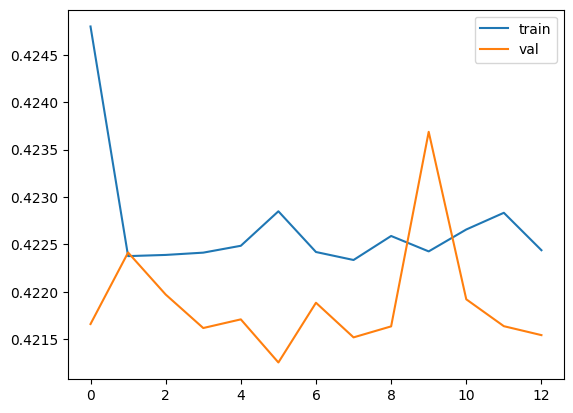

In [32]:
process_and_evaluate1(
    tft_top100_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\tft_top100.keras',epochs=30,batch_size=16
)

In [33]:
tft_top100_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\tft_top100.keras')

In [34]:
pred_probs_test = tft_top100_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = tft_top100_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [35]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [36]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [37]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [38]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [39]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.850343,0.494451,0.0,0.0,0.0,"[[36552, 0], [6433, 0]]",Train
1,0.892102,0.478374,0.0,0.0,0.0,"[[9624, 0], [1164, 0]]",Test


In [43]:
model_name = 'tft_top100'
top_n = 30

In [40]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [44]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_1260\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_1260\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_1260\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.099111,0.128044,NaN,0.832432,-0.019376,0.733322,0.118486,0.704389,...,0,363,347,391,28,44,0,92,88,94
1,2005-06-30,Train,0.213342,0.281427,NaN,0.952000,0.045476,0.738659,0.167866,0.670574,...,0,362,345,390,28,45,0,93,90,95
2,2005-09-30,Train,0.051938,0.029358,NaN,0.331440,0.244277,0.279501,-0.192338,0.302082,...,0,364,348,387,23,39,0,91,87,98
3,2005-12-31,Train,0.163028,0.149742,NaN,0.682739,0.058583,0.519711,0.104445,0.532998,...,0,364,345,388,24,43,0,91,90,97
4,2006-03-31,Train,-0.137250,-0.135527,NaN,0.254938,0.187746,0.392188,-0.324996,0.390464,...,0,365,348,391,26,43,0,95,92,99


In [45]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.True_

In [46]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [47]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.15768482, 0.15768456, 0.15767658, ..., 0.12838836, 0.1283874 ,
       0.12838082], dtype=float32)

In [48]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,9624,0,1164,32,9296,328,1132,60,9084,540,1104
Train,0,36552,0,6433,268,34780,1772,6165,469,33621,2931,5964


In [49]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [50]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.8647, precision=0.0889, recall=0.0275, f1=0.0420
Train: accuracy=0.8154, precision=0.1314, recall=0.0417, f1=0.0633

Metrics for _Top50:
Test: accuracy=0.8476, precision=0.1000, recall=0.0515, f1=0.0680
Train: accuracy=0.7931, precision=0.1379, recall=0.0729, f1=0.0954

Metrics for _Thresh:
Test: accuracy=0.8921, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.8503, precision=0.0000, recall=0.0000, f1=0.0000


In [51]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [52]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.15768482, 0.15768456, 0.15767658, ..., 0.12838836, 0.1283874 ,
       0.12838082], dtype=float32)

In [54]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.146794
std          0.013951
min          0.062015
25%          0.128384
50%          0.157340
75%          0.157341
max          0.180509
Name: Pred_Prob_tft_top100, dtype: float64

In [55]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [394]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,9624,0,1164,42,9306,318,1122,59,9083,541,1105
Train,0,36552,0,6433,349,34861,1691,6084,558,33710,2842,5875


In [56]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_1260\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_1260\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behav

In [397]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.275761,0.217428,0.0,0.832432,-0.019376,0.556671,0.295137,0.615004,...,0,370,352,391,21,39,0,85,83,94
1,2005-06-30,Train,0.225005,0.212999,0.0,0.952000,0.045476,0.726996,0.179529,0.739002,...,0,365,347,390,25,43,0,90,88,95
2,2005-09-30,Train,0.051089,0.068485,0.0,0.331440,0.244277,0.280350,-0.193188,0.262955,...,0,360,346,387,27,41,0,95,89,98
3,2005-12-31,Train,0.178021,0.168024,0.0,0.682739,0.058583,0.504718,0.119438,0.514715,...,0,364,348,388,24,40,0,91,87,97
4,2006-03-31,Train,-0.118426,-0.112497,0.0,0.254938,0.187746,0.373363,-0.306171,0.367434,...,0,365,349,391,26,42,0,95,91,99


In [398]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_tft_top100,Set,Top_30_Pred_Prob_tft_top100,Top_50_Pred_Prob_tft_top100,Pred_Category_Top30,Pred_Category_Top50
0,ade,2024-12-31,0,NaN,NaN,0.15486,Test,True,True,FP,FP
1,adani,2024-12-31,0,-0.038058,159.0,0.15486,Test,True,True,FP,FP
2,bjaut,2024-12-31,0,-0.104534,275.0,0.15486,Test,True,True,FP,FP
3,irfc,2024-12-31,0,-0.165191,383.0,0.15486,Test,True,True,FP,FP
4,zyduslif,2024-12-31,0,NaN,NaN,0.15486,Test,True,True,FP,FP


In [399]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.275761,0.217428,9,370,21,85,11,352,39,83,0.832432,-0.019376,0.556671,0.295137,0.615004,0.236804
1,2005-06-30,Train,0.225005,0.212999,5,365,25,90,7,347,43,88,0.952000,0.045476,0.726996,0.179529,0.739002,0.167523
2,2005-09-30,Train,0.051089,0.068485,3,360,27,95,9,346,41,89,0.331440,0.244277,0.280350,-0.193188,0.262955,-0.175792
3,2005-12-31,Train,0.178021,0.168024,6,364,24,91,10,348,40,87,0.682739,0.058583,0.504718,0.119438,0.514715,0.109441
4,2006-03-31,Train,-0.118426,-0.112497,4,365,26,95,8,349,42,91,0.254938,0.187746,0.373363,-0.306171,0.367434,-0.300242


In [400]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [401]:
model_name

'tft_top100'

In [58]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top100\3yrs_as_test_data_ts\Pred_Vs_Act_TFT_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top100 xform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [434]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [10]:
df_train['Target'] = np.where(df_train['Rank']<=100,1,0)
df_test['Target'] = np.where(df_test['Rank']<=100,1,0)

In [11]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [12]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [13]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [14]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transforms = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transforms[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [15]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [16]:
df_test[df_test['Quarter']=='31-03-2021']['Target'].value_counts()

Series([], Name: count, dtype: int64)

#### Power xforms

In [17]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }

def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transforms.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 1, 11)
y_train shape: (42985,)
X_test shape: (10788, 1, 11)
y_test shape: (10788,)


In [18]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [19]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [20]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [21]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [22]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [23]:
features = vif_cols.copy()
features.append("Quarter")

In [24]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [25]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### TFT

In [26]:
from tensorflow.keras.layers import Input, Dense, LayerNormalization, Dropout, MultiHeadAttention, GRU, Concatenate, Embedding, Flatten, RepeatVector
from tensorflow.keras.models import Model

def gated_residual_network(x, hidden_units, dropout_rate=0.1):
    dense1 = Dense(hidden_units, activation='elu')(x)
    dropout = Dropout(dropout_rate)(dense1)
    dense2 = Dense(x.shape[-1])(dropout)
    gated_output = tf.keras.layers.Add()([x, dense2])
    norm = LayerNormalization()(gated_output)
    return norm

def build_tft_top100_xform_model(input_shape, embedding_size, num_tickers, num_heads=4, hidden_units=16):
    # Inputs
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)

    # Merge static and temporal inputs
    merged_input = Concatenate(axis=-1)([ticker_embedding, continuous_input])

    # Gated Residual Network
    grn_output = gated_residual_network(merged_input, hidden_units)

    # Multi-Head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=hidden_units)(grn_output, grn_output)
    attention_output = LayerNormalization()(attention_output + grn_output)

    # Temporal processing (GRU)
    rnn_output = GRU(hidden_units, return_sequences=False)(attention_output)

    # Output layer
    output = Dense(1, activation='sigmoid')(rnn_output)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [27]:
num_tickers = len(label_encoder.classes_)

In [28]:

# Define tft model
tft_top100_xform_model = build_tft_top100_xform_model(X_train.shape, embedding_size, num_tickers)
tft_top100_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [29]:
X_train.shape

(42985, 1, 11)

In [31]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top100_xform.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Qua

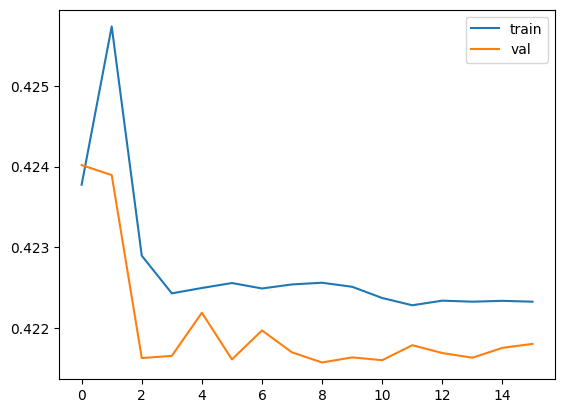

In [32]:
process_and_evaluate1(
    tft_top100_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\tft_top100_xform.keras',epochs=30,batch_size=16
)

In [33]:
tft_top100_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\tft_top100_xform.keras')

In [34]:
pred_probs_test = tft_top100_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = tft_top100_xform_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step


In [470]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [471]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [35]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [36]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [37]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.850343,0.501260,0.0,0.0,0.0,"[[36552, 0], [6433, 0]]",Train
1,0.892102,0.497282,0.0,0.0,0.0,"[[9624, 0], [1164, 0]]",Test


In [38]:
model_name = 'tft_top100_xform'
top_n = 30

In [39]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [40]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_33312\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_33312\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_33312\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.094853,0.088643,NaN,0.832432,-0.019376,0.737579,0.114229,0.743789,...,0,363,343,391,28,48,0,92,92,94
1,2005-06-30,Train,0.219013,0.251050,NaN,0.952000,0.045476,0.732987,0.173537,0.700951,...,0,361,346,390,29,44,0,94,89,95
2,2005-09-30,Train,0.087395,0.102829,NaN,0.331440,0.244277,0.244044,-0.156882,0.228610,...,0,362,347,387,25,40,0,93,88,98
3,2005-12-31,Train,0.243981,0.270573,NaN,0.682739,0.058583,0.438758,0.185398,0.412166,...,0,362,351,388,26,37,0,93,84,97
4,2006-03-31,Train,-0.095264,-0.108848,NaN,0.254938,0.187746,0.350201,-0.283010,0.363786,...,0,365,348,391,26,43,0,95,92,99


In [41]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.True_

In [480]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [42]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.15305899, 0.15305635, 0.15305634, 0.14464393, 0.14464392,
       0.10414366, 0.10289583, 0.17686425, 0.1766091 , 0.15305726,
       0.15305693, 0.15305647, 0.15305643, 0.15305638, 0.15360928,
       0.15305641, 0.14464387, 0.1766327 , 0.20293526, 0.17699581,
       0.15306345, 0.13619047, 0.15310237, 0.14463732, 0.15307444,
       0.15305704], dtype=float32)

In [43]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,9624,0,1164,15,9279,345,1149,30,9054,570,1134
Train,0,36552,0,6433,252,34764,1788,6181,442,33594,2958,5991


In [44]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [45]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.8615, precision=0.0417, recall=0.0129, f1=0.0197
Train: accuracy=0.8146, precision=0.1235, recall=0.0392, f1=0.0595

Metrics for _Top50:
Test: accuracy=0.8420, precision=0.0500, recall=0.0258, f1=0.0340
Train: accuracy=0.7918, precision=0.1300, recall=0.0687, f1=0.0899

Metrics for _Thresh:
Test: accuracy=0.8921, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.8503, precision=0.0000, recall=0.0000, f1=0.0000


In [46]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [47]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [48]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.15305899, 0.15305635, 0.15305634, 0.14464393, 0.14464392,
       0.10414366, 0.10289583, 0.17686425, 0.1766091 , 0.15305726,
       0.15305693, 0.15305647, 0.15305643, 0.15305638, 0.15360928,
       0.15305641, 0.14464387, 0.1766327 , 0.20293526, 0.17699581,
       0.15306345, 0.13619047, 0.15310237, 0.14463732, 0.15307444,
       0.15305704], dtype=float32)

In [49]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.150279
std          0.004074
min          0.102896
25%          0.144644
50%          0.153056
75%          0.153056
max          0.202935
Name: Pred_Prob_tft_top100_xform, dtype: float64

In [50]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [490]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,9624,0,1164,34,9298,326,1130,55,9079,545,1109
Train,0,36552,0,6433,317,34829,1723,6116,539,33691,2861,5894


In [51]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [52]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_33312\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_33312\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [493]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.233524,0.207458,0.0,0.832432,-0.019376,0.598909,0.252899,0.624974,...,0,368,353,391,23,38,0,87,82,94
1,2005-06-30,Train,0.234022,0.426775,0.0,0.952000,0.045476,0.717979,0.188546,0.525225,...,0,365,348,390,25,42,0,90,87,95
2,2005-09-30,Train,0.106445,0.082248,0.0,0.331440,0.244277,0.224994,-0.137832,0.249191,...,0,364,350,387,23,37,0,91,85,98
3,2005-12-31,Train,0.205351,0.234418,0.0,0.682739,0.058583,0.477389,0.146767,0.448321,...,0,366,351,388,22,37,0,89,84,97
4,2006-03-31,Train,0.064245,0.056733,0.0,0.254938,0.187746,0.190693,-0.123501,0.198204,...,0,369,352,391,22,39,0,91,88,99


In [494]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_tft_top100_xform,Set,Top_30_Pred_Prob_tft_top100_xform,Top_50_Pred_Prob_tft_top100_xform,Pred_Category_Top30,Pred_Category_Top50
0,delhiver,2024-12-31,0,-0.263036,594.0,0.224252,Test,True,True,FP,FP
1,aiae,2024-12-31,0,-0.014974,133.0,0.169998,Test,True,True,FP,FP
2,areal,2024-12-31,0,-0.165091,382.0,0.169998,Test,True,True,FP,FP
3,acc,2024-12-31,0,NaN,NaN,0.169998,Test,True,True,FP,FP
4,happyfor,2024-12-31,0,-0.212018,488.0,0.169997,Test,True,True,FP,FP


In [495]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.233524,0.207458,7,368,23,87,12,353,38,82,0.832432,-0.019376,0.598909,0.252899,0.624974,0.226834
1,2005-06-30,Train,0.234022,0.426775,5,365,25,90,8,348,42,87,0.952000,0.045476,0.717979,0.188546,0.525225,0.381299
2,2005-09-30,Train,0.106445,0.082248,7,364,23,91,13,350,37,85,0.331440,0.244277,0.224994,-0.137832,0.249191,-0.162028
3,2005-12-31,Train,0.205351,0.234418,8,366,22,89,13,351,37,84,0.682739,0.058583,0.477389,0.146767,0.448321,0.175835
4,2006-03-31,Train,0.064245,0.056733,8,369,22,91,11,352,39,88,0.254938,0.187746,0.190693,-0.123501,0.198204,-0.131013


In [496]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [53]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top100\3yrs_as_test_data_ts\Pred_Vs_Act_TFT_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 200 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
df_train['Target'] = np.where(df_train['Rank']<=200,1,0)
df_test['Target'] = np.where(df_test['Rank']<=200,1,0)

##### Scaling

In [10]:
scaler = StandardScaler()

In [11]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [507]:
# df_train.drop()

In [12]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [509]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [13]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [14]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [15]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [16]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [17]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [18]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [516]:
# df_train1['Ticker_Encoded']

In [19]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [20]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [21]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [22]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 1, 11)
y_train shape: (42985,)
X_test shape: (10788, 1, 11)
y_test shape: (10788,)


In [23]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [24]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### TFT

In [25]:
from tensorflow.keras.layers import Input, Dense, LayerNormalization, Dropout, MultiHeadAttention, GRU, Concatenate, Embedding, Flatten, RepeatVector
from tensorflow.keras.models import Model

def gated_residual_network(x, hidden_units, dropout_rate=0.1):
    dense1 = Dense(hidden_units, activation='elu')(x)
    dropout = Dropout(dropout_rate)(dense1)
    dense2 = Dense(x.shape[-1])(dropout)
    gated_output = tf.keras.layers.Add()([x, dense2])
    norm = LayerNormalization()(gated_output)
    return norm

def build_tft_top200_model(input_shape, embedding_size, num_tickers, num_heads=4, hidden_units=16):
    # Inputs
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)

    # Merge static and temporal inputs
    merged_input = Concatenate(axis=-1)([ticker_embedding, continuous_input])

    # Gated Residual Network
    grn_output = gated_residual_network(merged_input, hidden_units)

    # Multi-Head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=hidden_units)(grn_output, grn_output)
    attention_output = LayerNormalization()(attention_output + grn_output)

    # Temporal processing (GRU)
    rnn_output = GRU(hidden_units, return_sequences=False)(attention_output)

    # Output layer
    output = Dense(1, activation='sigmoid')(rnn_output)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [26]:
df_test1[df_test1['Quarter']=='2006-03-31']['Target'].value_counts()

Series([], Name: count, dtype: int64)

In [27]:
num_tickers = len(label_encoder.classes_)

In [28]:

# Define tft model
tft_top200_model = build_tft_top200_model(X_train.shape, embedding_size, num_tickers)
tft_top200_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [603]:
X_train.shape

(42985, 1, 11)

In [604]:
y_train.shape

(42985,)

In [29]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top20

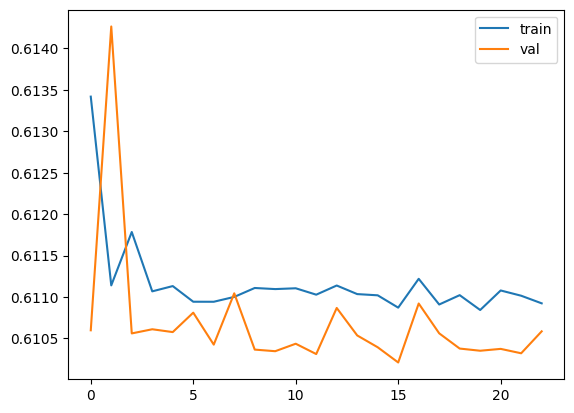

In [30]:
process_and_evaluate1(
    tft_top200_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\tft_top200.keras',epochs=30,batch_size=16
)

In [31]:
tft_top200_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\tft_top200.keras')

In [32]:
pred_probs_test = tft_top200_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = tft_top200_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step


In [33]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [34]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [35]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [36]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [37]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.700407,0.500277,0.0,0.0,0.0,"[[30107, 0], [12878, 0]]",Train
1,0.784390,0.502976,0.0,0.0,0.0,"[[8462, 0], [2326, 0]]",Test


In [38]:
model_name = 'tft_top200'
top_n = 30

In [39]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [40]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_41372\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_41372\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_41372\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.088941,0.073765,NaN,0.532415,-0.019376,0.443474,0.108317,0.458650,...,0,273,255,294,21,39,0,182,180,191
1,2005-06-30,Train,0.248429,0.276505,NaN,0.645971,0.045476,0.397542,0.202953,0.369466,...,0,275,261,291,16,30,0,180,174,194
2,2005-09-30,Train,0.076984,0.089649,NaN,0.231957,0.244277,0.154973,-0.167292,0.142308,...,0,272,264,287,15,23,0,183,171,198
3,2005-12-31,Train,0.285599,0.290730,NaN,0.471668,0.058583,0.186069,0.227016,0.180938,...,0,280,273,288,8,15,0,175,162,197
4,2006-03-31,Train,-0.133974,-0.134215,NaN,0.085933,0.187746,0.219907,-0.321720,0.220148,...,0,277,264,293,16,29,0,183,176,197


In [41]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.True_

In [617]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [42]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.3018266 , 0.2840582 , 0.28405815, 0.284058  , 0.39024425,
       0.30181387, 0.28405818, 0.28405812, 0.28405672, 0.28405562,
       0.2837742 , 0.2329605 , 0.28405625], dtype=float32)

In [43]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,8462,0,2326,48,8150,312,2278,91,7953,509,2235
Train,0,30107,0,12878,628,28695,1412,12250,1066,27773,2334,11812


In [44]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [45]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7599, precision=0.1333, recall=0.0206, f1=0.0357
Train: accuracy=0.6822, precision=0.3078, recall=0.0488, f1=0.0842

Metrics for _Top50:
Test: accuracy=0.7456, precision=0.1517, recall=0.0391, f1=0.0622
Train: accuracy=0.6709, precision=0.3135, recall=0.0828, f1=0.1310

Metrics for _Thresh:
Test: accuracy=0.7844, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.7004, precision=0.0000, recall=0.0000, f1=0.0000


In [46]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [47]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [48]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.3018266 , 0.2840582 , 0.28405815, 0.284058  , 0.39024425,
       0.30181387, 0.28405818, 0.28405812, 0.28405672, 0.28405562,
       0.2837742 , 0.2329605 , 0.28405625], dtype=float32)

In [49]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.293820
std          0.008909
min          0.232961
25%          0.284058
50%          0.301827
75%          0.301827
max          0.390244
Name: Pred_Prob_tft_top200, dtype: float64

In [50]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [627]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,8462,0,2326,63,8165,297,2263,96,7958,504,2230
Train,0,30107,0,12878,640,28707,1400,12238,1083,27790,2317,11795


In [51]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [52]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_41372\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_41372\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [53]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.088941,0.073765,0.0,0.532415,-0.019376,0.443474,0.108317,0.458650,...,0,273,255,294,21,39,0,182,180,191
1,2005-06-30,Train,0.248429,0.276505,0.0,0.645971,0.045476,0.397542,0.202953,0.369466,...,0,275,261,291,16,30,0,180,174,194
2,2005-09-30,Train,0.076984,0.089649,0.0,0.231957,0.244277,0.154973,-0.167292,0.142308,...,0,272,264,287,15,23,0,183,171,198
3,2005-12-31,Train,0.285599,0.290730,0.0,0.471668,0.058583,0.186069,0.227016,0.180938,...,0,280,273,288,8,15,0,175,162,197
4,2006-03-31,Train,-0.133974,-0.134215,0.0,0.085933,0.187746,0.219907,-0.321720,0.220148,...,0,277,264,293,16,29,0,183,176,197


In [631]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_tft_top200,Set,Top_30_Pred_Prob_tft_top200,Top_50_Pred_Prob_tft_top200,Pred_Category_Top30,Pred_Category_Top50
0,str,2024-12-31,1,0.014862,102.0,0.364125,Test,True,True,TP,TP
1,pec,2024-12-31,0,-0.248028,555.0,0.364089,Test,True,True,FP,FP
2,info,2024-12-31,0,NaN,NaN,0.364049,Test,True,True,FP,FP
3,ltim,2024-12-31,0,-0.195949,444.0,0.341855,Test,True,True,FP,FP
4,tcs,2024-12-31,0,-0.119334,301.0,0.307121,Test,True,True,FP,FP


In [632]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.111455,0.105815,9,273,21,182,14,258,36,177,0.532415,-0.019376,0.420960,0.130831,0.426600,0.125191
1,2005-06-30,Train,0.231179,0.267120,13,274,17,181,22,263,28,172,0.645971,0.045476,0.414792,0.185703,0.378850,0.221645
2,2005-09-30,Train,0.097877,0.086439,17,274,13,181,26,263,24,172,0.231957,0.244277,0.134081,-0.146400,0.145519,-0.157838
3,2005-12-31,Train,0.244922,0.265568,17,275,13,180,33,271,17,164,0.471668,0.058583,0.226746,0.186339,0.206100,0.206985
4,2006-03-31,Train,-0.083532,-0.124367,14,277,16,183,22,265,28,175,0.085933,0.187746,0.169465,-0.271277,0.210300,-0.312113


In [633]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [54]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top200\3yrs_as_test_data_ts\Pred_Vs_Act_TFT_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top200 xform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [636]:
# train_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\train_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# test_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\test_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# master_data_path = r"D:\FY25-26\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

# df_train = pd.read_excel(train_data_path)
# df_test = pd.read_excel(test_data_path)
# df_master = pd.read_excel(master_data_path)

# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"


In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [638]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [5]:
df_test['Quarter'].unique()

<DatetimeArray>
['2022-03-31 00:00:00', '2022-06-30 00:00:00', '2022-09-30 00:00:00',
 '2022-12-31 00:00:00', '2023-03-31 00:00:00', '2023-06-30 00:00:00',
 '2023-09-30 00:00:00', '2023-12-31 00:00:00', '2024-03-31 00:00:00',
 '2024-06-30 00:00:00', '2024-09-30 00:00:00', '2024-12-31 00:00:00']
Length: 12, dtype: datetime64[ns]

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [644]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [10]:
df_train['Target'] = np.where(df_train['Rank']<=200,1,0)
df_test['Target'] = np.where(df_test['Rank']<=200,1,0)

In [11]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [647]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [12]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [13]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transforms = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transforms[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [14]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [15]:
df_test[df_test['Quarter']=='31-03-2021']['Target'].value_counts()

Series([], Name: count, dtype: int64)

#### Power xforms

In [16]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }

def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transforms.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 1, 11)
y_train shape: (42985,)
X_test shape: (10788, 1, 11)
y_test shape: (10788,)


In [17]:
check = pd.Series(y_train)
check.unique()

array([1, 0])

In [18]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [19]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [20]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [21]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [22]:
features = vif_cols.copy()
features.append("Quarter")

In [23]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [24]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### TFT

In [25]:
from tensorflow.keras.layers import Input, Dense, LayerNormalization, Dropout, MultiHeadAttention, GRU, Concatenate, Embedding, Flatten, RepeatVector
from tensorflow.keras.models import Model

def gated_residual_network(x, hidden_units, dropout_rate=0.1):
    dense1 = Dense(hidden_units, activation='elu')(x)
    dropout = Dropout(dropout_rate)(dense1)
    dense2 = Dense(x.shape[-1])(dropout)
    gated_output = tf.keras.layers.Add()([x, dense2])
    norm = LayerNormalization()(gated_output)
    return norm

def build_tft_top200_xform_model(input_shape, embedding_size, num_tickers, num_heads=4, hidden_units=16):
    # Inputs
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)

    # Merge static and temporal inputs
    merged_input = Concatenate(axis=-1)([ticker_embedding, continuous_input])

    # Gated Residual Network
    grn_output = gated_residual_network(merged_input, hidden_units)

    # Multi-Head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=hidden_units)(grn_output, grn_output)
    attention_output = LayerNormalization()(attention_output + grn_output)

    # Temporal processing (GRU)
    rnn_output = GRU(hidden_units, return_sequences=False)(attention_output)

    # Output layer
    output = Dense(1, activation='sigmoid')(rnn_output)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [26]:
num_tickers = len(label_encoder.classes_)

In [27]:

# Define tft model
tft_top200_xform_model = build_tft_top200_xform_model(X_train.shape, embedding_size, num_tickers)
tft_top200_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [667]:
X_train.shape

(42985, 1, 11)

In [28]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 1: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 1: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 1: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 2: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 2: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 2: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 2: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 3: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft_top200_xform.keras

Epoch 3: saving model to D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\tft

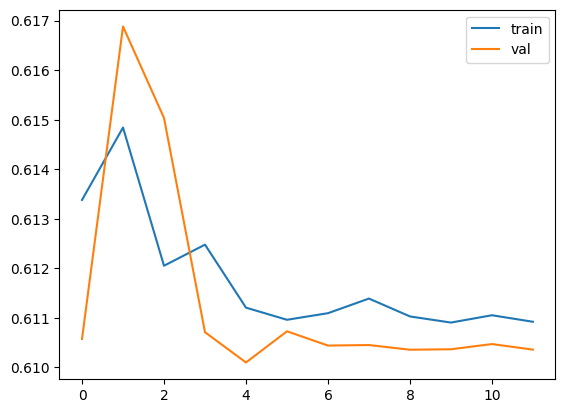

In [668]:
process_and_evaluate1(
    tft_top200_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\tft_top200_xform.keras',epochs=30,batch_size=16
)

In [29]:
tft_top200_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\tft_top200_xform.keras')

In [30]:
pred_probs_test = tft_top200_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = tft_top200_xform_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step


In [671]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [672]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [31]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [32]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [33]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.700407,0.500964,0.0,0.0,0.0,"[[30107, 0], [12878, 0]]",Train
1,0.784390,0.496658,0.0,0.0,0.0,"[[8462, 0], [2326, 0]]",Test


In [34]:
model_name = 'tft_top200_xform'
top_n = 30

In [35]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [36]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_33816\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_33816\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_33816\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.090611,0.107631,NaN,0.532415,-0.019376,0.441804,0.109987,0.424784,...,0,274,261,294,20,33,0,181,174,191
1,2005-06-30,Train,0.277836,0.288264,NaN,0.645971,0.045476,0.368135,0.232360,0.357706,...,0,278,265,291,13,26,0,177,170,194
2,2005-09-30,Train,0.057441,0.067092,NaN,0.231957,0.244277,0.174517,-0.186836,0.164866,...,0,271,262,287,16,25,0,184,173,198
3,2005-12-31,Train,0.261810,0.300051,NaN,0.471668,0.058583,0.209858,0.203226,0.171617,...,0,278,274,288,10,14,0,177,161,197
4,2006-03-31,Train,-0.141594,-0.143758,NaN,0.085933,0.187746,0.227528,-0.329340,0.229691,...,0,274,260,293,19,33,0,186,180,197


In [37]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.True_

In [38]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [39]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.32045218, 0.2933471 , 0.2171338 , 0.19597365, 0.1918207 ,
       0.32045186, 0.30967388, 0.13817891, 0.21840155, 0.13781017,
       0.32878348, 0.29334706, 0.3105006 , 0.29334712, 0.25074068,
       0.30965826], dtype=float32)

In [40]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,8462,0,2326,46,8148,314,2280,79,7941,521,2247
Train,0,30107,0,12878,626,28693,1414,12252,1075,27782,2325,11803


In [41]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [42]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7595, precision=0.1278, recall=0.0198, f1=0.0343
Train: accuracy=0.6821, precision=0.3069, recall=0.0486, f1=0.0839

Metrics for _Top50:
Test: accuracy=0.7434, precision=0.1317, recall=0.0340, f1=0.0540
Train: accuracy=0.6713, precision=0.3162, recall=0.0835, f1=0.1321

Metrics for _Thresh:
Test: accuracy=0.7844, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.7004, precision=0.0000, recall=0.0000, f1=0.0000


In [43]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [44]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [45]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.32045218, 0.2933471 , 0.2171338 , 0.19597365, 0.1918207 ,
       0.32045186, 0.30967388, 0.13817891, 0.21840155, 0.13781017,
       0.32878348, 0.29334706, 0.3105006 , 0.29334712, 0.25074068,
       0.30965826], dtype=float32)

In [46]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.308094
std          0.013840
min          0.137810
25%          0.293347
50%          0.320452
75%          0.320452
max          0.328783
Name: Pred_Prob_tft_top200_xform, dtype: float64

In [47]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [690]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,8462,0,2326,46,8148,314,2280,79,7941,521,2247
Train,0,30107,0,12878,626,28693,1414,12252,1075,27782,2325,11803


In [48]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [49]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_33816\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_33816\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [693]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.090611,0.107631,0.0,0.532415,-0.019376,0.441804,0.109987,0.424784,...,0,274,261,294,20,33,0,181,174,191
1,2005-06-30,Train,0.277836,0.288264,0.0,0.645971,0.045476,0.368135,0.232360,0.357706,...,0,278,265,291,13,26,0,177,170,194
2,2005-09-30,Train,0.057441,0.067092,0.0,0.231957,0.244277,0.174517,-0.186836,0.164866,...,0,271,262,287,16,25,0,184,173,198
3,2005-12-31,Train,0.261810,0.300051,0.0,0.471668,0.058583,0.209858,0.203226,0.171617,...,0,278,274,288,10,14,0,177,161,197
4,2006-03-31,Train,-0.141594,-0.143758,0.0,0.085933,0.187746,0.227528,-0.329340,0.229691,...,0,274,260,293,19,33,0,186,180,197


In [694]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_tft_top200_xform,Set,Top_30_Pred_Prob_tft_top200_xform,Top_50_Pred_Prob_tft_top200_xform,Pred_Category_Top30,Pred_Category_Top50
0,reliance,2024-12-31,0,NaN,NaN,0.320452,Test,True,True,FP,FP
1,bharti,2024-12-31,1,0.091734,56.0,0.320452,Test,True,True,TP,TP
2,sbin,2024-12-31,0,NaN,NaN,0.320452,Test,True,True,FP,FP
3,huvr,2024-12-31,0,NaN,NaN,0.320452,Test,True,True,FP,FP
4,lt,2024-12-31,0,NaN,NaN,0.320452,Test,True,True,FP,FP


In [695]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.090611,0.107631,10,274,20,181,17,261,33,174,0.532415,-0.019376,0.441804,0.109987,0.424784,0.127006
1,2005-06-30,Train,0.277836,0.288264,17,278,13,177,24,265,26,170,0.645971,0.045476,0.368135,0.232360,0.357706,0.242789
2,2005-09-30,Train,0.057441,0.067092,14,271,16,184,25,262,25,173,0.231957,0.244277,0.174517,-0.186836,0.164866,-0.177185
3,2005-12-31,Train,0.261810,0.300051,20,278,10,177,36,274,14,161,0.471668,0.058583,0.209858,0.203226,0.171617,0.241467
4,2006-03-31,Train,-0.141594,-0.143758,11,274,19,186,17,260,33,180,0.085933,0.187746,0.227528,-0.329340,0.229691,-0.331503


In [696]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [50]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top200\3yrs_as_test_data_ts\Pred_Vs_Act_TFT_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')